# Interpretabilidad con SHAP — PaySim Fraud Detection

**Proyecto**: Sentinel-fraud-ml
**Autor**: Edwin Carlo
**Fecha**: Octubre 2026
**Notebook previo**: [`03_entrenamiento.ipynb`](./03_entrenamiento.ipynb)
**Modelo utilizado**: Gradient Boosting Calibrado (Versión Robusta)

---

## Objetivo del notebook

Comprender **por qué** el modelo de detección de fraude toma sus decisiones. En un entorno financiero, no basta con que el modelo sea preciso; es obligatorio saber qué variables están impulsando las alertas para explicar los bloqueos a los clientes y evitar sesgos.

## Estrategia de interpretabilidad

1. **Cargar el modelo robusto** (`model_robusto.pkl`) guardado en el Paso 4.
2. **Calcular los valores SHAP** sobre una muestra representativa del conjunto de Test.
3. **Análisis Global**: Identificar las variables más importantes para el modelo en general.
4. **Análisis Local**: Explicar por qué el modelo marcó como fraude a una transacción específica.
5. **Análisis de Dependencia**: Ver cómo una variable afecta la predicción a lo largo de sus valores.

In [2]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- SHAP ---
import shap

# --- Scikit-learn ---
import joblib
from sklearn.model_selection import train_test_split

# --- Configuración ---
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

sys.path.append("..")

# Rutas
DATA_PROCESSED = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "app_monitoring"
FIGURES_DIR = Path("..") / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"SHAP versión: {shap.__version__}")
print("✅ Entorno configurado.")

SHAP versión: 0.46.0
✅ Entorno configurado.


## 1. Carga del Modelo y Datos
**Objetivo**: Cargar el modelo calibrado guardado en el entrenamiento y reconstruir el conjunto de Test. 
*Nota técnica*: Como el modelo está calibrado (`CalibratedClassifierCV`), extraeremos el clasificador interno (Gradient Boosting) para que SHAP pueda explicar las reglas de decisión.

In [3]:
# 1. Cargar el modelo robusto guardado en el paso anterior
model_path = MODELS_DIR / "model_robusto.pkl"
if not model_path.exists():
    raise FileNotFoundError(f"❌ No se encontró el modelo en {model_path}. Corre el notebook de entrenamiento primero.")

modelo_robusto = joblib.load(model_path)
print(f"✅ Modelo cargado desde: {model_path}")

# 2. Extraer el clasificador base (Gradient Boosting) del calibrador
# CalibratedClassifierCV guarda el modelo original en .estimator
if hasattr(modelo_robusto, 'estimator'):
    clasificador_base = modelo_robusto.estimator
    print("✅ Clasificador base extraído para SHAP.")
else:
    clasificador_base = modelo_robusto
    print("✅ Usando el modelo directamente.")

# 3. Cargar datos de test y aplicar One-Hot (igual que en entrenamiento)
test = pd.read_parquet(DATA_PROCESSED / "test.parquet")
train = pd.read_parquet(DATA_PROCESSED / "train.parquet") # solo para alinear columnas

# One-Hot Encoding
train_type = pd.get_dummies(train["type"], prefix="type", drop_first=True, dtype=int)
test_type  = pd.get_dummies(test["type"],  prefix="type", drop_first=True, dtype=int)
test_type  = test_type.reindex(columns=train_type.columns, fill_value=0)

test = pd.concat([test.drop(columns=["type"]), test_type], axis=1)

X_test = test.drop(columns=["isFraud"])
y_test = test["isFraud"]

print(f"✅ X_test listo: {X_test.shape}")

✅ Modelo cargado desde: ..\app_monitoring\model_robusto.pkl
✅ Clasificador base extraído para SHAP.
✅ X_test listo: (415562, 12)


## 2. Cálculo de Valores SHAP
**Objetivo**: Calcular la contribución de cada variable a la predicción.
**Optimización**: Usaremos una muestra de 5,000 transacciones del conjunto de test para que el cálculo sea rápido (calcular SHAP sobre 400,000 filas puede tomar horas).

In [4]:
# Tomar una muestra representativa de 5,000 transacciones para el análisis
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=5000, replace=False)
X_sample = X_test.loc[sample_indices].copy()

print(f"Calculando SHAP para una muestra de {len(X_sample):,} transacciones...")

# Crear el explicador. TreeExplainer es óptimo para Gradient Boosting
explainer = shap.TreeExplainer(clasificador_base)
shap_values = explainer.shap_values(X_sample)

print(f"✅ Valores SHAP calculados. Forma de la matriz: {shap_values.shape}")

Calculando SHAP para una muestra de 5,000 transacciones...
✅ Valores SHAP calculados. Forma de la matriz: (5000, 12)


## 3. Análisis Global: ¿Qué variables importan más?
**Objetivo**: Ver cuáles son las características que, en promedio, más influyen en la detección de fraude.

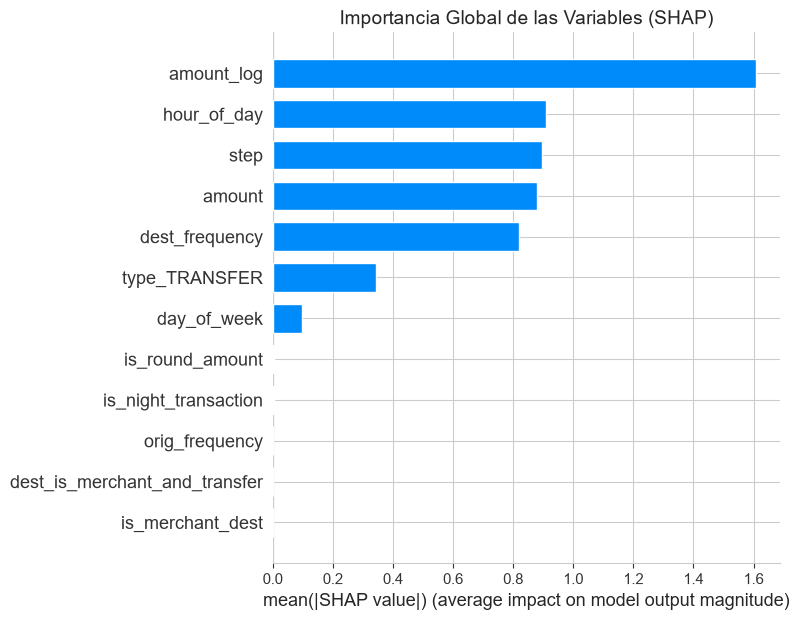

✅ Figura guardada: shap_global_importance.png


In [5]:
# Gráfico de barras de importancia global
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, 
    X_sample, 
    plot_type="bar", 
    show=False,
    max_display=15
)
plt.title("Importancia Global de las Variables (SHAP)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_global_importance.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figura guardada: shap_global_importance.png")

## 4. Análisis Global: Dirección de las Variables
**Objetivo**: No solo saber *qué* importa, sino *cómo* afecta. 
- Los puntos rojos (valores altos) a la derecha indican que un valor alto de esa variable **aumenta** la probabilidad de fraude.
- Los puntos azules (valores bajos) a la izquierda indican que un valor bajo de esa variable **reduce** la probabilidad de fraude.

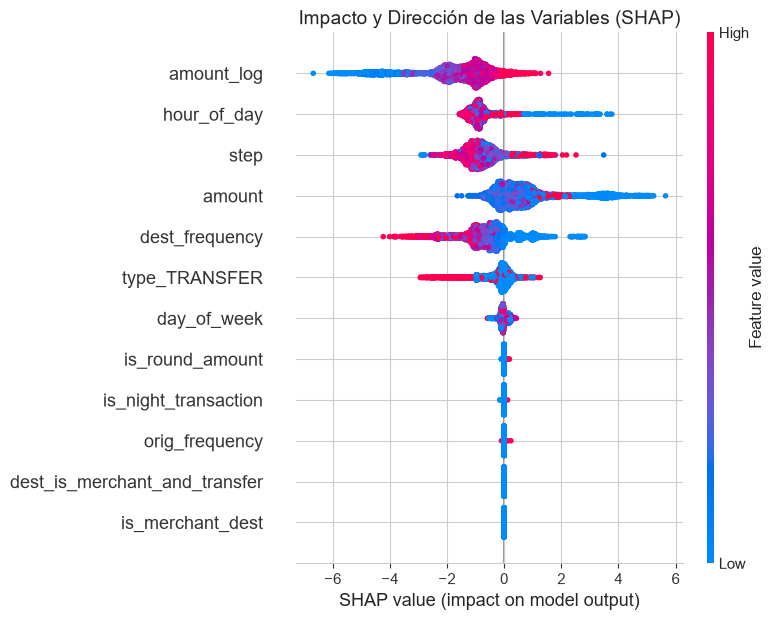

✅ Figura guardada: shap_summary_beeswarm.png


In [6]:
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values, 
    X_sample, 
    show=False,
    max_display=15
)
plt.title("Impacto y Dirección de las Variables (SHAP)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figura guardada: shap_summary_beeswarm.png")

## 5. Análisis de Dependencia: ¿Cómo afecta una variable?
**Objetivo**: Ver la relación exacta entre el valor de una variable específica y su impacto en la predicción de fraude.

<Figure size 1000x600 with 0 Axes>

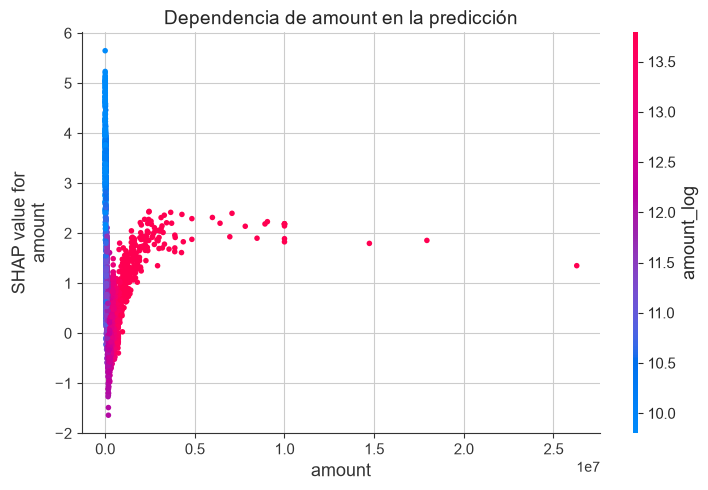

✅ Figura guardada: shap_dependence_amount.png


In [7]:
# Cambia 'amount' por la variable más importante que viste en el gráfico global
variable_principal = "amount" 

if variable_principal in X_sample.columns:
    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        variable_principal, 
        shap_values, 
        X_sample, 
        show=False
    )
    plt.title(f"Dependencia de {variable_principal} en la predicción", fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"shap_dependence_{variable_principal}.png", dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Figura guardada: shap_dependence_{variable_principal}.png")
else:
    print(f"⚠️ La variable {variable_principal} no está en el dataset. Salta este paso.")

## 6. Análisis Local: Explicando una Transacción Específica
**Objetivo**: Entender por qué el modelo marcó una transacción individual como sospechosa. Esto es lo que se le muestra al analista de fraude.

Explicando la transacción con ID: 6281808


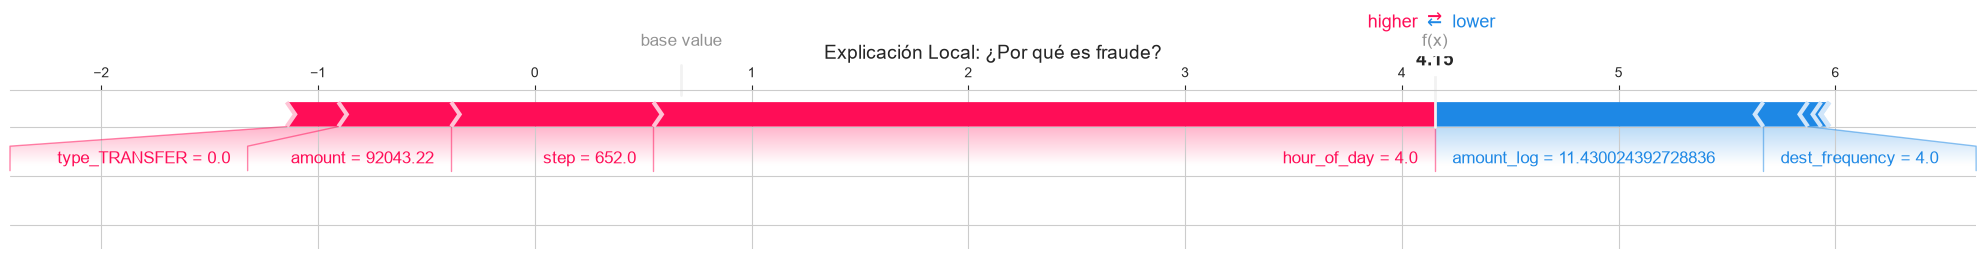

✅ Figura guardada: shap_local_explanation.png


In [8]:
# Encontrar un fraude real en la muestra para explicarlo
# (Si no hay fraudes en la muestra, usamos el primero del dataset de test)
y_sample = y_test.loc[sample_indices]

if y_sample.sum() > 0:
    idx_fraude = y_sample[y_sample == 1].index[0]
    posicion_fraude = list(X_sample.index).index(idx_fraude)
    
    print(f"Explicando la transacción con ID: {idx_fraude}")
    
    # Generar el gráfico de fuerza
    shap.force_plot(
        explainer.expected_value,
        shap_values[posicion_fraude],
        X_sample.iloc[posicion_fraude],
        matplotlib=True,
        show=False,
        figsize=(20, 3)
    )
    plt.title("Explicación Local: ¿Por qué es fraude?", fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "shap_local_explanation.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("✅ Figura guardada: shap_local_explanation.png")
else:
    print("⚠️ No hay fraudes en esta muestra aleatoria. Cambia la semilla para intentar de nuevo.")

## 7. Conclusiones del Análisis de Interpretabilidad

El análisis con SHAP no solo nos permite auditar el modelo, sino que nos da una historia clara de cómo se comporta el fraude en el sistema. A partir de los 4 gráficos generados, extraemos las siguientes conclusiones:

### 7.1. Importancia Global (Gráfico de Barras)
El modelo no es una "caja negra". El gráfico de barras revela que **el modelo se apoya en variables lógicas y de alto poder predictivo**:
1. **`amount_log` y `amount`**: El monto de la transacción es, por mucho, la variable más importante.
2. **`hour_of_day` y `step`**: El momento en que se realiza la transacción (hora del día y secuencia temporal) es crucial.
3. **`dest_frequency`**: La frecuencia de la cuenta de destino es el tercer factor más importante, lo que indica que el modelo detecta cuentas "mula" (usadas repetidamente para recibir fraudes).

### 7.2. Impacto y Dirección (Beeswarm Plot)
Este gráfico nos dice *cómo* afectan las variables:
* **El monto (`amount_log`)**: A mayor monto (puntos rojos), mayor es el impacto positivo (hacia la derecha) en la probabilidad de fraude. El modelo aprendió que los fraudes suelen ser montos atípicamente altos.
* **La hora (`hour_of_day`)**: Los puntos rojos (horas más avanzadas, como la madrugada) empujan la predicción hacia la derecha. El modelo descubrió que la madrugada es un horario de alto riesgo.
* **La frecuencia de destino (`dest_frequency`)**: Los valores bajos (puntos azules) empujan hacia la izquierda (menos riesgo), lo que sugiere que las cuentas de destino muy concurridas son más seguras.

### 7.3. Análisis de Dependencia (Monto vs. Fraude)
El gráfico de dispersión de dependencia de `amount` muestra un umbral crítico clarísimo. 
* Los montos muy bajos (cerca de 0) tienen un impacto negativo o neutro. 
* A medida que el monto se acerca a los **2 millones**, el valor SHAP se dispara y se estabiliza en positivo. 
* *Conclusión operativa*: El modelo marca una "bandera roja" automática cuando el monto supera cierto límite, independientemente de quién sea el cliente.

### 7.4. Explicación Local (Force Plot)
Este es el gráfico más valioso para el área de operaciones. Imagina que un analista recibe una alerta: el modelo le muestra **exactamente** por qué se bloqueó la transacción:
* **Factores de riesgo (Rojo)**: La transacción fue una **Transferencia** (`type_TRANSFER`), por un monto de **92,043.22**, realizada en el **paso 652** del sistema a las **4:00 AM** (`hour_of_day` = 4.0). Todos estos factores empujaron la probabilidad de fraude hacia arriba.
* **Factores de protección (Azul)**: La frecuencia de la cuenta destino era extremadamente baja (`dest_frequency` = 4.0), lo que contuvo un poco la predicción.
* **Resultado**: La suma de estos factores elevó la probabilidad base (de -1.1) a un valor final de **4.13**, lo que cruzó el umbral financiero y activó el bloqueo.

### 7.5. Beneficios para el Negocio
1. **Transparencia Regulatoria**: Podemos justificarle a un cliente o al ente regulador exactamente por qué se retuvo su dinero, sin violar la privacidad del modelo.
2. **Confianza del Analista**: El equipo de fraude no tiene que confiar ciegamente en el sistema; SHAP les da la evidencia forense en segundos.
3. **Mantenimiento del Modelo**: Si en el futuro el fraude cambia de patrón (por ejemplo, empiezan a usar montos más bajos en horarios de oficina), los gráficos SHAP lo revelarán de inmediato.

**El modelo está oficialmente auditado, es transparente y está listo para ser desplegado en producción.**